In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time
import scipy
import pandas as pd
#import tensorflow as tf
import traceSpace as tSp

#print(tf.config.list_physical_devices('GPU'))
#print("TensorFlow version:", tf.__version__)

from scipy import optimize, special
from scipy import linalg
from scipy.sparse.linalg import eigsh
from scipy.sparse.linalg import spsolve
from scipy.sparse import diags
from scipy.sparse import identity

In [2]:
#bdsim format ['x','y','z','px','py','pz','xp','yp','E']
#               0  1    2   3    4    5    6    7   8
bdsim_part = [2.4365, -6.69078, 220.0, -0.0003664405859721, 0.0047474444745605, 1.3413900972351782, -0.0002731797242367597, 0.003539182719821641, 1.34864]
m = 0.139
p = (bdsim_part[8]**2-m**2)**0.5
print((bdsim_part[5]*bdsim_part[6]-bdsim_part[3])/bdsim_part[3])

-2.4875720715210014e-08


In [3]:
he = np.arange(4)+1
data = {'Name': ['Pandas', 'Geeks', 'for', 'Geeks'],
        'Height': he,#[1, 2, 3, 4]
        'Qualification': ['A', 'B', 'C', 'D']}

df = pd.DataFrame(data)

address = ['NewYork', 'Chicago', 'Boston', 'Miami']

# Using 'Address' as the column name
# and equating it to the list
df['Address'] = address

display(df)
print(df.iloc[0])
print(df['Height'][3])

,Name,Height,Qualification,Address
0,Pandas,1,A,NewYork
1,Geeks,2,B,Chicago
2,for,3,C,Boston
3,Geeks,4,D,Miami


Name              Pandas
Height                 1
Qualification          A
Address          NewYork
Name: 0, dtype: object
4


In [10]:
df1 = pd.DataFrame(
    {
        "A": ["A0", "A1", "A2", "A3"],
        "B": ["B0", "B1", "B2", "B3"],
        "C": ["C0", "C1", "C2", "C3"],
        "D": ["D0", "D1", "D2", "D3"],
    }
)

df4 = pd.DataFrame(
    {
        "B": ["B2", "B3", "B6", "B7"],
        "D": ["D2", "D3", "D6", "D7"],
        "F": ["F2", "F3", "F6", "F7"],
    }
)

result = pd.concat([df1, df4], axis=1)

display(result)

,A,B,C,D,B,D,F
0,A0,B0,C0,D0,B2,D2,F2
1,A1,B1,C1,D1,B3,D3,F3
2,A2,B2,C2,D2,B6,D6,F6
3,A3,B3,C3,D3,B7,D7,F7


In [2]:
np.zeros((2, 3, 4), dtype="float32")

array([[[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]],

       [[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]]], dtype=float32)

In [5]:
a = np.array([[1,2,3],[1,2,3],[1,2,3]])
b = np.array([[1,2,3],[1,2,3],[1,2,3]])
print(a)
print(a@b)

[[1 2 3]
 [1 2 3]
 [1 2 3]]
[[ 6 12 18]
 [ 6 12 18]
 [ 6 12 18]]


In [2]:
J = np.array([[0,1],[-1,0]])
trans = np.array([[0.563266, 11.451137],[-0.048097,  0.357646]]) 
(trans.T)@J@trans

array([[ 0.        ,  0.75221517],
       [-0.75221517,  0.        ]])

In [12]:
symp = (trans.T)@J@trans
print(symp[0][1]+symp[1][0])

0.0


In [3]:
J = np.array([[0,1],[-1,0]])
trans = np.array([[-0.012381, 21.302075],[-0.047158,  0.011372]]) 
(trans.T)@J@trans

array([[ 0.        ,  1.00442246],
       [-1.00442246,  0.        ]])

In [8]:
J = np.array([[0,1],[-1,0]])
trans = np.array([[0.273087, 8.299676],[-0.071631, 0.114399]]) 
(trans.T)@J@trans

array([[ 0.        ,  0.62575497],
       [-0.62575497,  0.        ]])

In [3]:
scipy.special.comb(1000,500)

np.float64(2.7028824094560503e+299)

In [7]:
def exact_vote_prob(total_num, vote_a, vote_b):
    p_a = vote_a/total_num
    p_b = vote_b/total_num
    p_ex = 1-p_a-p_b
    prob = scipy.special.comb(total_num,vote_a)*scipy.special.comb(total_num-vote_a,vote_b)*(p_a**vote_a)*(p_b**vote_b)*(p_ex**(total_num-vote_a-vote_b))
    return prob

def exact_vote_prob_approx(total_num, vote_a, vote_b):
    p_a = vote_a/total_num
    p_b = vote_b/total_num
    p_ex = 1-p_a-p_b
    ln_prob = comb_log(total_num,vote_a)+comb_log(total_num-vote_a,vote_b)+vote_a*np.log(p_a)+vote_b*np.log(p_b)+(total_num-vote_a-vote_b)*np.log(p_ex)
    print(ln_prob)
    prob = np.exp(ln_prob)
    return prob

def Stirling_form(n):#approx n!
    ln_n_fac = n*np.log(n)-n+0.5*np.log(2*np.pi*n)
    n_fac = np.exp(ln_n_fac)
    return n_fac

def Stirling_form_log(n):#approx ln(n!)
    ln_n_fac = n*np.log(n)-n+0.5*np.log(2*np.pi*n)    
    return ln_n_fac

def comb_log(n,m):#approx ln(nCm)
    if n==0 or m ==0 or n-m == 0:
        return 0
    ln_n_fac = Stirling_form_log(n)
    ln_m_fac = Stirling_form_log(m)
    ln_n_m_fac = Stirling_form_log(n-m)
    return ln_n_fac - (ln_m_fac + ln_n_m_fac)

In [8]:
print(str(exact_vote_prob(820,400,400)*100)+"%")
print(str(exact_vote_prob_approx(820,400,400)*100)+"%")

0.25363304673544057%
-5.972555580165022
0.25477221840477887%


In [6]:
num = 170
print(str(num)+"! = "+str(scipy.special.factorial(num)))
print(str(num)+"! approx "+str(Stirling_form(num)))
print(str(num)+"! real to approx diff "+str(scipy.special.factorial(num)/Stirling_form(num)-1))

170! = 7.257415615308e+306
170! approx 7.253858934543497e+306
170! real to approx diff 0.0004903156783993001


In [3]:
1.003333**300

2.713494696443505

In [2]:
mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

In [3]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dropout(0.2),
  tf.keras.layers.Dense(10)
])

In [4]:
predictions = model(x_train[:1]).numpy()
predictions

array([[ 0.1706447 ,  0.33120346, -0.4012763 ,  0.3601361 , -1.1592964 ,
        -0.45704976,  0.11097185,  0.25537154,  0.43496555, -0.10464417]],
      dtype=float32)

In [5]:
tf.nn.softmax(predictions).numpy()

array([[0.11314846, 0.13285515, 0.06386553, 0.13675514, 0.02992696,
        0.06040103, 0.10659406, 0.12315302, 0.14738107, 0.08591959]],
      dtype=float32)

In [6]:
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
loss_fn(y_train[:1], predictions).numpy()

model.compile(optimizer='adam', loss=loss_fn, metrics=['accuracy'])

In [7]:
model.fit(x_train, y_train, epochs=20)
model.evaluate(x_test,  y_test, verbose=2)

Epoch 1/20
1875/1875 [==============================] - 9s 4ms/step - loss: 0.2989 - accuracy: 0.9136
Epoch 2/20
1875/1875 [==============================] - 9s 5ms/step - loss: 0.1451 - accuracy: 0.9561
Epoch 3/20
1875/1875 [==============================] - 10s 5ms/step - loss: 0.1080 - accuracy: 0.9672
Epoch 4/20
1875/1875 [==============================] - 9s 5ms/step - loss: 0.0897 - accuracy: 0.9725
Epoch 5/20
1875/1875 [==============================] - 11s 6ms/step - loss: 0.0754 - accuracy: 0.9767
Epoch 6/20
1875/1875 [==============================] - 11s 6ms/step - loss: 0.0663 - accuracy: 0.9789
Epoch 7/20
1875/1875 [==============================] - 12s 6ms/step - loss: 0.0572 - accuracy: 0.9820
Epoch 8/20
1875/1875 [==============================] - 12s 6ms/step - loss: 0.0515 - accuracy: 0.9833
Epoch 9/20
1875/1875 [==============================] - 8s 4ms/step - loss: 0.0464 - accuracy: 0.9843
Epoch 10/20
1875/1875 [==============================] - 8s 4ms/step - loss: 

[0.08207964152097702, 0.9810000061988831]

In [4]:
a= np.linspace(0,1,10)
b = a + 1
print(b-a)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [5]:
x = np.linspace(0,1,10)
print(len(x))

10


In [6]:
a = np.random.random(15)
b = np.sqrt(1-a**2)
print(a)
print(b)
print(a**2+b**2)

[0.09194336 0.77995017 0.14933763 0.63503007 0.45613461 0.01581949
 0.25347929 0.26161087 0.77796505 0.42813787 0.07765242 0.71863254
 0.97334546 0.99483064 0.8171584 ]
[0.99576424 0.62584162 0.98878626 0.77248742 0.88991079 0.99987486
 0.96734081 0.96517343 0.62830755 0.90371343 0.99698049 0.69539001
 0.22934387 0.10154803 0.57641317]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [13]:
sample_part_num = 10
seq_num = 3
input_col_num = 6

a = np.zeros(sample_part_num*seq_num*input_col_num).reshape((sample_part_num,seq_num,input_col_num))
print(a.shape)

(10, 3, 6)


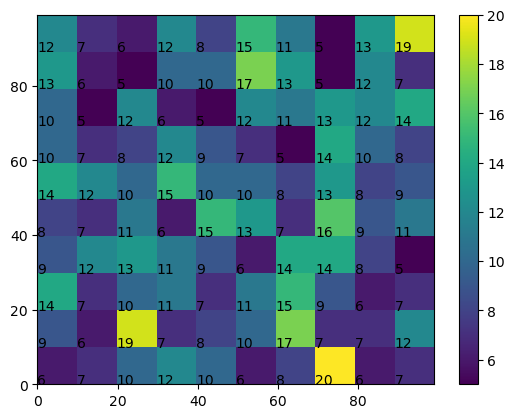

In [3]:
BINS = 10
x = [np.random.randint(0,100) for i in range(1000)]
y = [np.random.randint(0,100) for i in range(1000)]

h2D = plt.hist2d(x, y, bins=BINS)

# for bin in h2D[0]:
#     print(bin)

for ix, x_pos in enumerate(h2D[1][0:BINS]):
    for iy, y_pos in enumerate(h2D[2][0:BINS]):
        label = int(h2D[0][ix][iy])
        # print(f"bin({int(x_pos)},{int(y_pos)}): {int(label)}")
        plt.text(x_pos, y_pos, label)

plt.colorbar()
plt.show()

[ 0.   9.9 19.8 29.7 39.6 49.5 59.4 69.3 79.2 89.1 99. ]


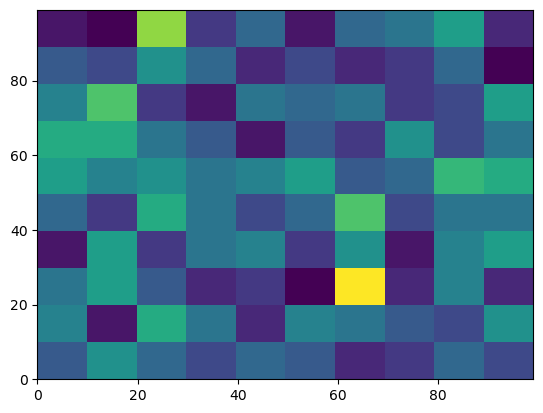

In [14]:
hist= plt.hist2d(x, y, bins=BINS, range=[[0, 99], [0, 99]])
print(hist[1])

In [15]:
a = np.linspace(0,1,11)
print(len(a))
print(a)
print(a[-1])
str_lst = ['ai', 'cq', 'ds', 'we', 'aa', 'he', 'hg', 'qw', 'kj', 'la', 'qw']
new_df = pd.DataFrame(a, columns=['num'])
new_df['str'] = str_lst
print(new_df)

11
[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
1.0
    num str
0   0.0  ai
1   0.1  cq
2   0.2  ds
3   0.3  we
4   0.4  aa
5   0.5  he
6   0.6  hg
7   0.7  qw
8   0.8  kj
9   0.9  la
10  1.0  qw


In [16]:
x_test = np.zeros(10).reshape((5,2))
print(x_test)

[[0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]]


In [17]:
a = np.arange(5)+[1,2,3,4,5]
print(a)
print(1/a)

[1 3 5 7 9]
[1.         0.33333333 0.2        0.14285714 0.11111111]


In [18]:
a = [1,2,3,4,5]
a = np.array(a)
b = [2,2,2,2,2]
b = np.array(b)
a**2

array([ 1,  4,  9, 16, 25])

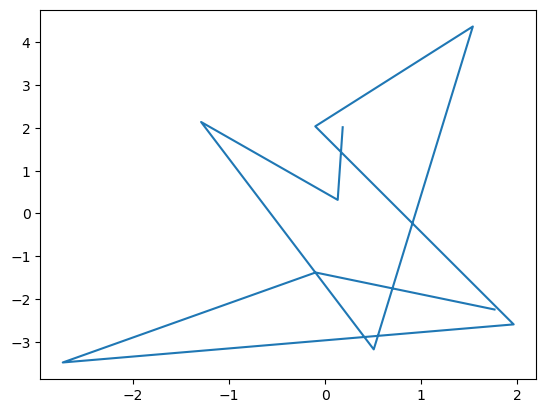

In [19]:
r = 5.
nSamples = 10
r_lst = r*np.random.random(nSamples)
x_lst = 2*r_lst*np.random.random(nSamples)-r_lst
y_lst = np.sqrt(r_lst**2-x_lst**2)#uniformy distribute x and y in circle of radius r
for i in range(0,len(y_lst)):
    if np.random.random()<0.5:
        y_lst[i] = -1*y_lst[i]

#print(r_lst)
#print(x_lst)
#print(y_lst)
plt.plot(x_lst, y_lst)
plt.show()

In [20]:
10**((115-90)/10)

316.22776601683796

In [21]:
np.sqrt(0.31623*27)

2.9220215604954047

In [22]:
16*44.1*1000*2/1e3

1411.2

In [23]:
np.random.random(3)

array([0.95406117, 0.6930768 , 0.60554844])

In [24]:
from numpy.random import default_rng
rng = default_rng()
def gen_data(t, a, b, c, noise=0., n_outliers=0, seed=None):
    rng = default_rng(seed)

    y = a + b * np.exp(t * c)

    error = noise * rng.standard_normal(t.size)
    outliers = rng.integers(0, t.size, n_outliers)
    error[outliers] *= 10

    return y + error

a = 0.5
b = 2.0
c = -1
t_min = 0
t_max = 10
n_points = 30

t_train = np.linspace(t_min, t_max, n_points)
y_train = gen_data(t_train, a, b, c, noise=0.1, n_outliers=0)

In [25]:
def fun(x, t, y):
    return x[0] + x[1] * np.exp(x[2] * t) - y

x0 = np.array([1.0, 1.0, 0.0])

In [26]:
res_lsq = optimize.least_squares(fun, x0, args=(t_train, y_train))

In [27]:
res_soft_l1 = optimize.least_squares(fun, x0, loss='soft_l1', f_scale=0.1,
                            args=(t_train, y_train))
res_log = optimize.least_squares(fun, x0, loss='cauchy', f_scale=0.1,
                        args=(t_train, y_train))

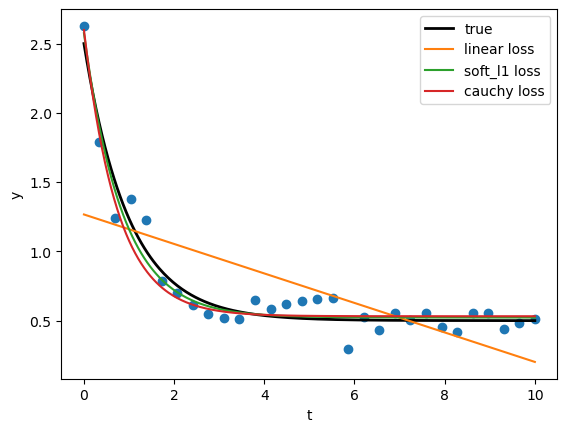

In [28]:
t_test = np.linspace(t_min, t_max, n_points * 10)
y_true = gen_data(t_test, a, b, c)
y_lsq = gen_data(t_test, *res_lsq.x)
y_soft_l1 = gen_data(t_test, *res_soft_l1.x)
y_log = gen_data(t_test, *res_log.x)

plt.plot(t_train, y_train, 'o')
plt.plot(t_test, y_true, 'k', linewidth=2, label='true')
plt.plot(t_test, y_lsq, label='linear loss')
plt.plot(t_test, y_soft_l1, label='soft_l1 loss')
plt.plot(t_test, y_log, label='cauchy loss')
plt.xlabel("t")
plt.ylabel("y")
plt.legend()
plt.show()

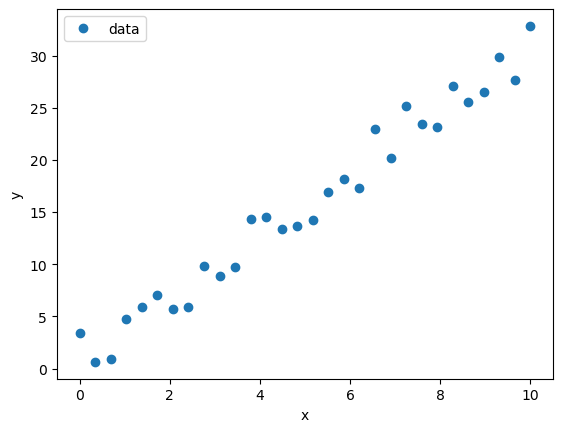

In [29]:
def lin_fun_with_noise(x, a, b, noise=0.):
    return a*x+b+noise*(np.random.random(len(x))-0.5)

def lin_fun_opt(par_lst, x, y):
    return par_lst[0]*x + par_lst[1] -y


a = 3
b = 1
x_min = 0
x_max = 10
n_points = 30
x_trn = np.linspace(x_min, x_max, n_points)
y_trn = lin_fun_with_noise(x_trn, a, b, noise=5)
plt.plot(x_trn, y_trn, 'o', label='data')

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [30]:
pars_0 = np.array([1.0, 1.0])

fit_lsq_sim = optimize.least_squares(lin_fun_opt, pars_0, args=(x_trn, y_trn))

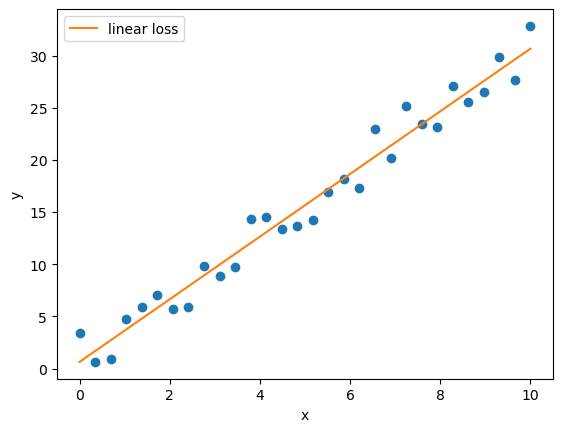

In [31]:
x_test = np.linspace(x_min, x_max, n_points*10)
y_lsq = lin_fun_with_noise(x_test, *fit_lsq_sim.x)

plt.plot(x_trn, y_trn, 'o')
plt.plot(x_test, y_lsq, label='linear loss')

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

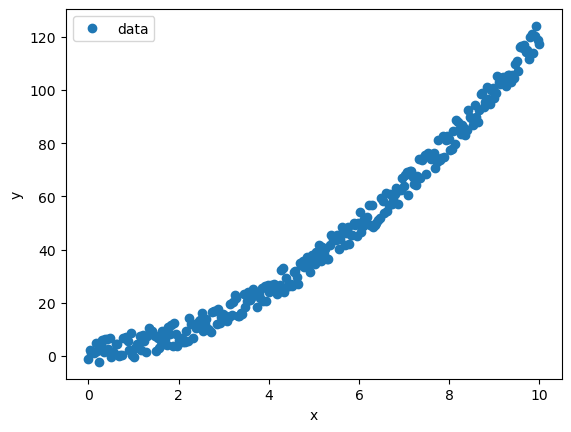

In [32]:
def quad_fun_with_noise(x, a, b, c, noise=0.):
    return a*x**2+b*x+c+noise*(np.random.random(len(x))-0.5)

def quad_fun_opt(par_lst, x, y):
    return par_lst[0]*x**2 + par_lst[1]*x + par_lst[2] -y

def quad_fun_opt_sigma(par_lst, x, y, sigma = 1.):
    trans = 1/sigma
    return sigma*(par_lst[0]*x**2 + par_lst[1]*x + par_lst[2] -y)

a = 1
b = 2
c = 1
x_min = 0
x_max = 10
n_points = 300
x_trn = np.linspace(x_min, x_max, n_points)
y_trn = quad_fun_with_noise(x_trn, a, b, c, noise=10)
plt.plot(x_trn, y_trn, 'o', label='data')

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [33]:
pars_0 = np.array([1.0, 1.0, 1.0])

fit_lsq_sim = optimize.least_squares(quad_fun_opt, pars_0, args=(x_trn, y_trn))#, loss='cauchy', f_scale=0.1

print(fit_lsq_sim)

     message: `xtol` termination condition is satisfied.
     success: True
      status: 3
         fun: [ 2.570e+00 -8.212e-01 ...  1.577e+00  3.757e+00]
           x: [ 1.019e+00  1.793e+00  1.358e+00]
        cost: 1258.113923004786
         jac: [[ 0.000e+00  0.000e+00  1.000e+00]
               [ 1.119e-03  3.344e-02  1.000e+00]
               ...
               [ 9.933e+01  9.967e+00  1.000e+00]
               [ 1.000e+02  1.000e+01  1.000e+00]]
        grad: [-2.908e-06 -1.041e-05 -4.838e-06]
  optimality: 1.0407971736015043e-05
 active_mask: [ 0.000e+00  0.000e+00  0.000e+00]
        nfev: 5
        njev: 3


In [34]:
sigma_array = np.zeros(len(y_trn))
sigma_array = y_trn
#print(y_trn)

fit_lsq_sim_sigma = optimize.least_squares(quad_fun_opt_sigma, pars_0, args=(x_trn, y_trn, sigma_array))#, loss='cauchy', f_scale=0.1

print(fit_lsq_sim_sigma)

     message: `xtol` termination condition is satisfied.
     success: True
      status: 3
         fun: [-5.403e+00  2.365e+00 ...  1.900e+02  4.434e+02]
           x: [ 1.031e+00  1.490e+00  3.245e+00]
        cost: 4324803.350893289
         jac: [[ 0.000e+00  0.000e+00 -1.212e+00]
               [ 2.506e-03  7.493e-02  2.240e+00]
               ...
               [ 1.181e+04  1.185e+03  1.189e+02]
               [ 1.174e+04  1.174e+03  1.174e+02]]
        grad: [ 1.723e-01 -1.457e-02 -2.485e-03]
  optimality: 0.17228278797119856
 active_mask: [ 0.000e+00  0.000e+00  0.000e+00]
        nfev: 8
        njev: 4


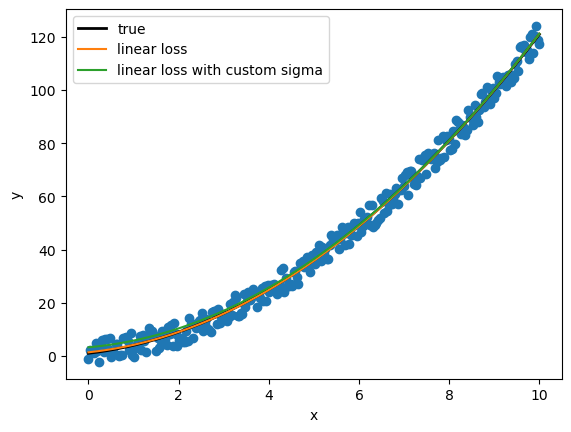

In [35]:
x_test = np.linspace(x_min, x_max, n_points*10)
y_true = quad_fun_with_noise(x_test, a,b,c)
y_lsq = quad_fun_with_noise(x_test, *fit_lsq_sim.x)
y_lsq_sigma = quad_fun_with_noise(x_test, *fit_lsq_sim_sigma.x)

plt.plot(x_trn, y_trn, 'o')
plt.plot(x_test, y_true, 'k', linewidth=2, label='true')
plt.plot(x_test, y_lsq, label='linear loss')
plt.plot(x_test, y_lsq_sigma, label='linear loss with custom sigma')

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [26]:
cost = 1350+325+865+3240+20520+124200
cost_diff = cost*0.3
b_per_round = 6000
repay_round = cost/b_per_round
margin_round = cost_diff/b_per_round
print(repay_round)
print(margin_round)

25.083333333333332
7.525


In [2]:
from datetime import datetime
def stair_sale_calc(start_date, end_date, ori_cost, sale_per_step, sale_interval):#계단식 세일 가격 계산, date form[year, month, date, time], interval in hour
    st_date_time = datetime(start_date[0], start_date[1], start_date[2], start_date[3], start_date[4])
    end_date_time = datetime(end_date[0], end_date[1], end_date[2], end_date[3], end_date[4])
    sale_time = (end_date_time - st_date_time)
    sale_time = int(sale_time.total_seconds()/3600) #to convert to hour
    final_cost = ori_cost - sale_per_step*int(1+sale_time/sale_interval)
    return final_cost

In [3]:
start = [2026,4,16,0,0]
end = [2026,4,28,14,17]
fin_cost = stair_sale_calc(start, end, 458, 2.5, 4)
print(fin_cost)

268.0
